# Home Work 3

## Task 1: Connect the Model to Real Data

**Dataset:** We are using the publicly available Hugging Face dataset `karan-0123/air-quality`.

**Data Table:** The data includes a timestamp (`datetime`), model inputs (wind speed `wind`, relative humidity `rh`), and a measured output (outdoor `pm25`).


c:\Users\Krisz\Desktop\egyetemi_cuccok\msc\digital_twin\DigitalTwin_Project_DE_IK\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,datetime,wind,rh,pm25
0,2015-01-01 00:00:00,0.1,42.058440,150.849670
1,2015-01-01 01:00:00,0.1,37.960572,132.370120
2,2015-01-01 02:00:00,0.1,37.412200,157.994518
3,2015-01-01 03:00:00,0.1,17.713272,173.358215
4,2015-01-01 04:00:00,0.1,39.903303,201.753827


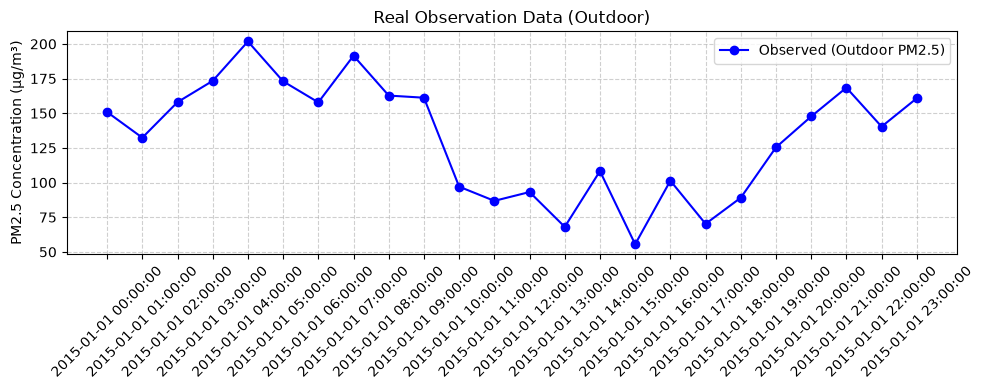

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load a sample of the historical dataset
df = pd.read_csv('hf://datasets/karan-0123/air-quality/air_quality.csv')
df_day = df[:24].copy() # Using 24 hours of data

# Display a small data table
display(df_day[['datetime', 'wind', 'rh', 'pm25']].head())

# Plot the observed output over time
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25'], label='Observed (Outdoor PM2.5)', color='blue', marker='o')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Real Observation Data (Outdoor)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 2: Compare Simulation and Observation

We use our existing model (Mass Balance Equation) to generate simulated indoor outputs for the same 24-hour period covered by the outdoor observational dataset.

**Discussion:**
- **Similarities/Differences:** The simulated indoor PM2.5 values are significantly smoother and react with a delay compared to the outdoor measurements.
- **Explanation:** This difference is expected because the simulation accounts for the building's infiltration rate (dependent on wind speed) and deposition rate (dependent on humidity). Furthermore, we are plotting simulated *indoor* air quality against measured *outdoor* air quality. Full alignment would require indoor sensor data.

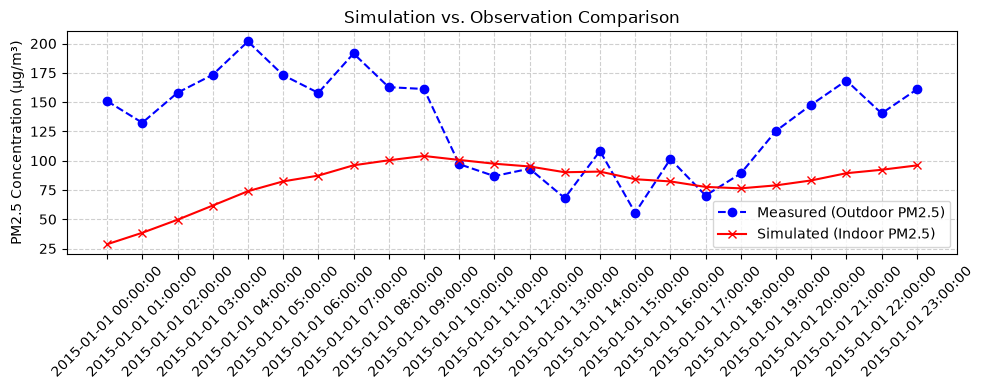

In [5]:
# Existing advanced simulation logic
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    PM_in_initial = 15.0
    PM_in_list = [PM_in_initial]
    
    for i in range(len(data)):
        PM_in_prev = PM_in_list[-1]
        PM_out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Dynamic parameters
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        
        # Calculate change
        change = delta_t * (k_v * (PM_out - PM_in_prev) - gamma_h * PM_in_prev + alpha_source - beta_purifier)
        PM_in_new = max(0, PM_in_prev + change)
        PM_in_list.append(PM_in_new)
        
    return PM_in_list[1:]

# Run simulation
simulated_pm25 = simulate_advanced_indoor_aq(df_day)

# Plotting the comparison
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25'], label='Measured (Outdoor PM2.5)', linestyle='--', color='blue', marker='o')
plt.plot(df_day['datetime'], simulated_pm25, label='Simulated (Indoor PM2.5)', color='red', marker='x')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Simulation vs. Observation Comparison')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 3: Design the Digital Twin Architecture

**Architecture Flow:**
1. **Physical System:** The building and its surrounding environment.
2. **Observations:** Outdoor Weather API (PM2.5, Wind, Humidity) & Indoor PM2.5 Sensor.
3. **Data Processing:** Handling missing values, duplicate timestamps, and data formatting.
4. **Simulation Model:** Extended Mass Balance Equation updating the state.
5. **Model Outputs:** Corrected and predicted Indoor Air Quality (PM2.5).

**Proposed Synchronization:**
When a new real observation is received from the physical indoor sensor, the internal state variable `$PM_{in}(t-1)$` in the simulation will be updated (overwritten) with this ground-truth value. This eliminates accumulating errors (drift) before the next time step is calculated.

## Task 4: Prepare for Week 4

**1. Which measured variable will you use to synchronize your Digital Twin?**

We will use the **indoor PM2.5 concentration** ($PM_{in}$) to synchronize the core state of the Digital Twin. The outdoor PM2.5 ($PM_{out}$) and weather parameters will be continuously updated as boundary conditions/inputs.

**2. How frequently can the model be updated?**

The model will be updated **hourly**. This matches both the frequency of the Hugging Face dataset (which provides hourly meteorological and air quality data) and the defined time step of our simulation ($\Delta t = 1$).

**3. How will you predict the next time step after synchronization?**

After synchronizing the state variable $PM_{in}(t-1)$ with the actual sensor measurement, we will plug this true value into the **Mass Balance Equation**. Using the newly received outdoor inputs (wind, humidity, outdoor PM2.5), the model will calculate the expected change over the next hour and output the predicted $PM_{in}(t)$ for the next time step.